# Saber 11 | Analítica educativa
Tres entregas sobre **resultados de 2010–2022**, con foco en modelos de regresión, procesamiento distribuido y redes neuronales tabulares. El extracto histórico tiene 7.109.704 filas y 51 columnas.

## Datos y alcance
Las tablas reproducen salidas guardadas de las entregas de la Universidad Nacional de Colombia. Los resultados de modelos corresponden a la evaluación de cada materia. [Datos Abiertos Colombia](https://www.datos.gov.co/es/Educaci-n/Resultados-nicos-Saber-11/kgxf-xxbe/data_preview).

In [1]:
from csv import DictReader
from pathlib import Path

def leer(archivo):
    with (Path('datos') / archivo).open(encoding='utf-8', newline='') as csv:
        return list(DictReader(csv))

def formato(n):
    return f'{n:,}'.replace(',', '.')

class Figura:
    def __init__(self, archivo):
        self.archivo = Path('figuras') / archivo

    def _repr_png_(self):
        return self.archivo.read_bytes()

## Big Data | Calidad de la ingesta

Filas en el CSV: 7.109.704
Claves únicas en Cassandra: 5.720.733
Diferencia de filas frente a claves: 1.388.971


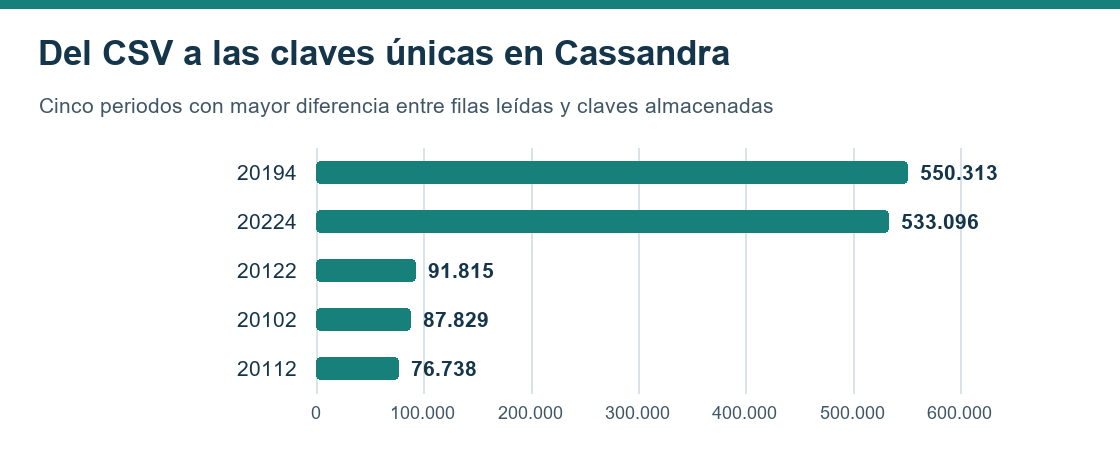

In [2]:
volumen = leer('registros_por_periodo.csv')
assert len({fila['periodo_original'] for fila in volumen}) == 23
for fila in volumen:
    assert int(fila['diferencia']) == int(fila['filas_csv']) - int(fila['claves_cassandra']) >= 0
entrada = sum(int(f['filas_csv']) for f in volumen)
almacenadas = sum(int(f['claves_cassandra']) for f in volumen)
assert entrada == 7_109_704 and almacenadas == 5_720_733
print('Filas en el CSV:', formato(entrada))
print('Claves únicas en Cassandra:', formato(almacenadas))
print('Diferencia de filas frente a claves:', formato(entrada - almacenadas))
display(Figura('diferencia_por_periodo.png'))

Cassandra preservó claves únicas por periodo y examen mediante *upsert*. Dask leyó por particiones. La diferencia cuantifica la reducción frente a la entrada y no comprueba que todas las filas con la misma clave fueran idénticas campo por campo.

## Machine Learning | Referencia y modelos supervisados

Histogram Gradient Boosting: MAE 29.53 · RMSE 37.04 puntos
XGBoost: MAE 29.57 · RMSE 37.08 puntos
Ridge: MAE 31.81 · RMSE 39.75 puntos
Media de entrenamiento: MAE 40.36 · RMSE 49.80 puntos


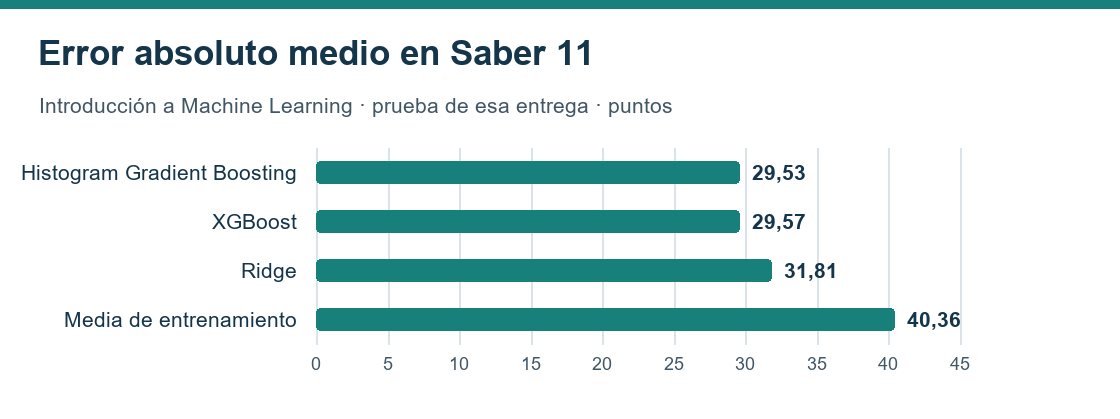

In [3]:
def mostrar_metricas(filename):
    metricas = leer(filename)
    for fila in metricas:
        print(f"{fila['modelo']}: MAE {fila['mae_test']} · RMSE {fila['rmse_test']} puntos")
    return metricas

ml = mostrar_metricas('metricas_machine_learning.csv')
assert float(ml[0]['mae_test']) < float(ml[-1]['mae_test'])
display(Figura('error_ml.png'))

## Deep Learning | Redes tabulares y transferencia

In [4]:
profundo = mostrar_metricas('metricas_deep_learning.csv')
assert {int(fila['filas_test']) for fila in profundo} == {339_584}
mejora = float(profundo[-1]['mae_test']) - float(profundo[0]['mae_test'])
print(f'Reducción de MAE frente a la mediana: {mejora:.2f} puntos')

MLP: MAE 29.88 · RMSE 37.56 puntos
Mediana de entrenamiento: MAE 40.26 · RMSE 49.91 puntos
Reducción de MAE frente a la mediana: 10.38 puntos


## Interpretación
Cada modelo se compara con su referencia dentro de la misma entrega. Deep Learning reportó que el ajuste fino no superó en promedio el entrenamiento solo en destino bajo su protocolo. Los resultados describen desempeño exploratorio y no son una herramienta para decidir sobre estudiantes individuales.

El script `contar_periodos.py` recalcula el volumen del CSV. Este cuaderno verifica y visualiza los resultados guardados y no vuelve a entrenar los modelos ni reconstruye Cassandra o Dask.